# Natural Component Alignment Summary

Load cached `natural_component_align` summaries and visualize component-wise best-layer and layer-wise alignment patterns.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'natural_component_align').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from natural_component_align.cache_summary import COMPILED_ROOT, DEFAULT_OUTPUT_ROOT, write_compiled_summaries
from natural_component_align.pipeline import DEFAULT_MODELS

MODEL_ORDER = list(DEFAULT_MODELS)
COMPONENT_ORDER = ['lowfreq', 'highfreq', 'envsounds', 'pitch', 'speech', 'music']
REG_METRIC = 'mean_r2'
RSA_METRIC = 'mean_spearman'

MODEL_COLORS = {
    model: plt.get_cmap('tab20')(i / max(1, len(MODEL_ORDER) - 1))
    for i, model in enumerate(MODEL_ORDER)
}
COMPONENT_COLORS = {
    component: plt.get_cmap('tab10')(i / max(1, len(COMPONENT_ORDER) - 1))
    for i, component in enumerate(COMPONENT_ORDER)
}

def refresh_component_summaries(output_root=DEFAULT_OUTPUT_ROOT, compiled_root=COMPILED_ROOT):
    reg_pkl, rsa_pkl = write_compiled_summaries(output_root=output_root, compiled_root=compiled_root)
    regression_all = pd.read_pickle(reg_pkl)
    rsa_all = pd.read_pickle(rsa_pkl)
    return regression_all, rsa_all

def ordered_present_models(frame):
    present = set(frame['model_name'].astype(str).unique())
    return [model for model in MODEL_ORDER if model in present]

def best_by_model_and_component(frame, metric_column):
    return (
        frame.sort_values(metric_column, ascending=False)
        .groupby(['model_name', 'component_name'], as_index=False)
        .head(1)
        .reset_index(drop=True)
    )

def add_relative_layer_position(frame):
    frame = frame.copy()
    max_depth = frame.groupby('model_name')['layer_depth'].transform('max').replace(0, 1)
    frame['relative_layer_position'] = frame['layer_depth'] / max_depth
    return frame

def plot_best_alignment_panels(regression_all, rsa_all):
    reg_best = best_by_model_and_component(regression_all, REG_METRIC)
    rsa_best = best_by_model_and_component(rsa_all, RSA_METRIC)

    fig, axes = plt.subplots(6, 2, figsize=(18, 24), constrained_layout=True)
    metric_specs = [
        ('Regression', reg_best, REG_METRIC, 'Best raw explained variance ($R^2$)'),
        ('RSA', rsa_best, RSA_METRIC, 'Best Spearman RSA'),
    ]

    for row_index, component_name in enumerate(COMPONENT_ORDER):
        for col_index, (title, table, metric_column, y_label) in enumerate(metric_specs):
            ax = axes[row_index, col_index]
            subset = table.loc[table['component_name'] == component_name].copy()
            if subset.empty:
                ax.set_axis_off()
                continue
            subset = subset.sort_values(metric_column, ascending=False)
            x_labels = subset['model_name'].tolist()
            x = np.arange(len(x_labels))
            colors = [MODEL_COLORS.get(model, '#4C72B0') for model in x_labels]
            ax.bar(x, subset[metric_column].to_numpy(), color=colors)
            ax.set_xticks(x)
            ax.set_xticklabels(x_labels, rotation=60, ha='right')
            ax.set_ylabel(y_label)
            if row_index == 0:
                ax.set_title(title, fontsize=13, fontweight='bold')
            ax.text(0.01, 0.95, component_name, transform=ax.transAxes, ha='left', va='top', fontsize=11, fontweight='bold')
            ax.grid(axis='y', alpha=0.2)

    return fig, axes

def plot_component_layerwise_all_models(regression_all, rsa_all, component_name='speech'):
    component_name = component_name.strip().lower()
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True, sharex=False)
    metric_specs = [
        ('Regression', regression_all, REG_METRIC, 'Layer-wise raw explained variance ($R^2$)'),
        ('RSA', rsa_all, RSA_METRIC, 'Layer-wise Spearman RSA'),
    ]

    for ax, (title, table, metric_column, y_label) in zip(axes, metric_specs):
        subset = table.loc[table['component_name'].str.lower() == component_name].copy()
        subset = add_relative_layer_position(subset)
        models = ordered_present_models(subset)
        for model_name in models:
            model_df = subset.loc[subset['model_name'] == model_name].sort_values('layer_depth')
            if model_df.empty:
                continue
            ax.plot(
                model_df['relative_layer_position'],
                model_df[metric_column],
                marker='o',
                markersize=3,
                linewidth=1.6,
                color=MODEL_COLORS.get(model_name, '#4C72B0'),
                label=model_name,
                alpha=0.95,
            )
            final_df = model_df.loc[model_df['is_final'].astype(bool)]
            if not final_df.empty:
                ax.scatter(
                    final_df['relative_layer_position'],
                    final_df[metric_column],
                    color=MODEL_COLORS.get(model_name, '#4C72B0'),
                    s=35,
                    edgecolor='black',
                    linewidth=0.4,
                    zorder=4,
                )
        ax.set_title(f'{title}: {component_name}', fontsize=13, fontweight='bold')
        ax.set_xlabel('Relative layer position')
        ax.set_ylabel(y_label)
        ax.set_xlim(-0.02, 1.02)
        ax.set_xticks(np.linspace(0, 1, 6))
        ax.set_xticklabels([f'{int(100 * tick)}%' for tick in np.linspace(0, 1, 6)])
        ax.grid(alpha=0.2)

    handles, labels = axes[-1].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
    return fig, axes

def plot_model_layerwise_all_components(regression_all, rsa_all, model_name='MERT'):
    model_name = model_name.strip().upper()
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True, sharex=False)
    metric_specs = [
        ('Regression', regression_all, REG_METRIC, 'Layer-wise raw explained variance ($R^2$)'),
        ('RSA', rsa_all, RSA_METRIC, 'Layer-wise Spearman RSA'),
    ]

    for ax, (title, table, metric_column, y_label) in zip(axes, metric_specs):
        subset = table.loc[table['model_name'].str.upper() == model_name].copy()
        subset = add_relative_layer_position(subset)
        for component_name in COMPONENT_ORDER:
            component_df = subset.loc[subset['component_name'].str.lower() == component_name].sort_values('layer_depth')
            if component_df.empty:
                continue
            ax.plot(
                component_df['relative_layer_position'],
                component_df[metric_column],
                marker='o',
                markersize=3,
                linewidth=1.8,
                color=COMPONENT_COLORS[component_name],
                label=component_name,
                alpha=0.95,
            )
            final_df = component_df.loc[component_df['is_final'].astype(bool)]
            if not final_df.empty:
                ax.scatter(
                    final_df['relative_layer_position'],
                    final_df[metric_column],
                    color=COMPONENT_COLORS[component_name],
                    s=35,
                    edgecolor='black',
                    linewidth=0.4,
                    zorder=4,
                )
        ax.set_title(f'{title}: {model_name}', fontsize=13, fontweight='bold')
        ax.set_xlabel('Relative layer position')
        ax.set_ylabel(y_label)
        ax.set_xlim(-0.02, 1.02)
        ax.set_xticks(np.linspace(0, 1, 6))
        ax.set_xticklabels([f'{int(100 * tick)}%' for tick in np.linspace(0, 1, 6)])
        ax.grid(alpha=0.2)

    handles, labels = axes[-1].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
    return fig, axes

regression_all, rsa_all = refresh_component_summaries()
print(f'Regression rows: {len(regression_all)}')
print(f'RSA rows: {len(rsa_all)}')
display(regression_all.head())


Regression rows: 1572
RSA rows: 1572


,model_name,representation_name,layer_index,component_name,mean_r2,median_r2,mean_train_r2,median_train_r2,mean_alpha,median_alpha,n_splits,source_dim,layer_depth,is_final,result_dir
0,CLAP,final,NaN,lowfreq,0.732778,0.733706,0.992950,0.997568,17.0,10.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
1,CLAP,final,NaN,highfreq,0.578873,0.579190,0.956974,0.961021,55.0,55.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
2,CLAP,final,NaN,envsounds,0.531932,0.526833,0.938374,0.919155,72.0,100.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
3,CLAP,final,NaN,pitch,0.756233,0.748336,0.997979,0.997404,7.1,10.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
4,CLAP,final,NaN,speech,0.836313,0.845660,0.997826,0.997616,9.0,10.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...


## 1. Best Alignment By Model

Each row is a component, each column is `regression` / `rsa`. Bars are sorted in descending order within each panel.

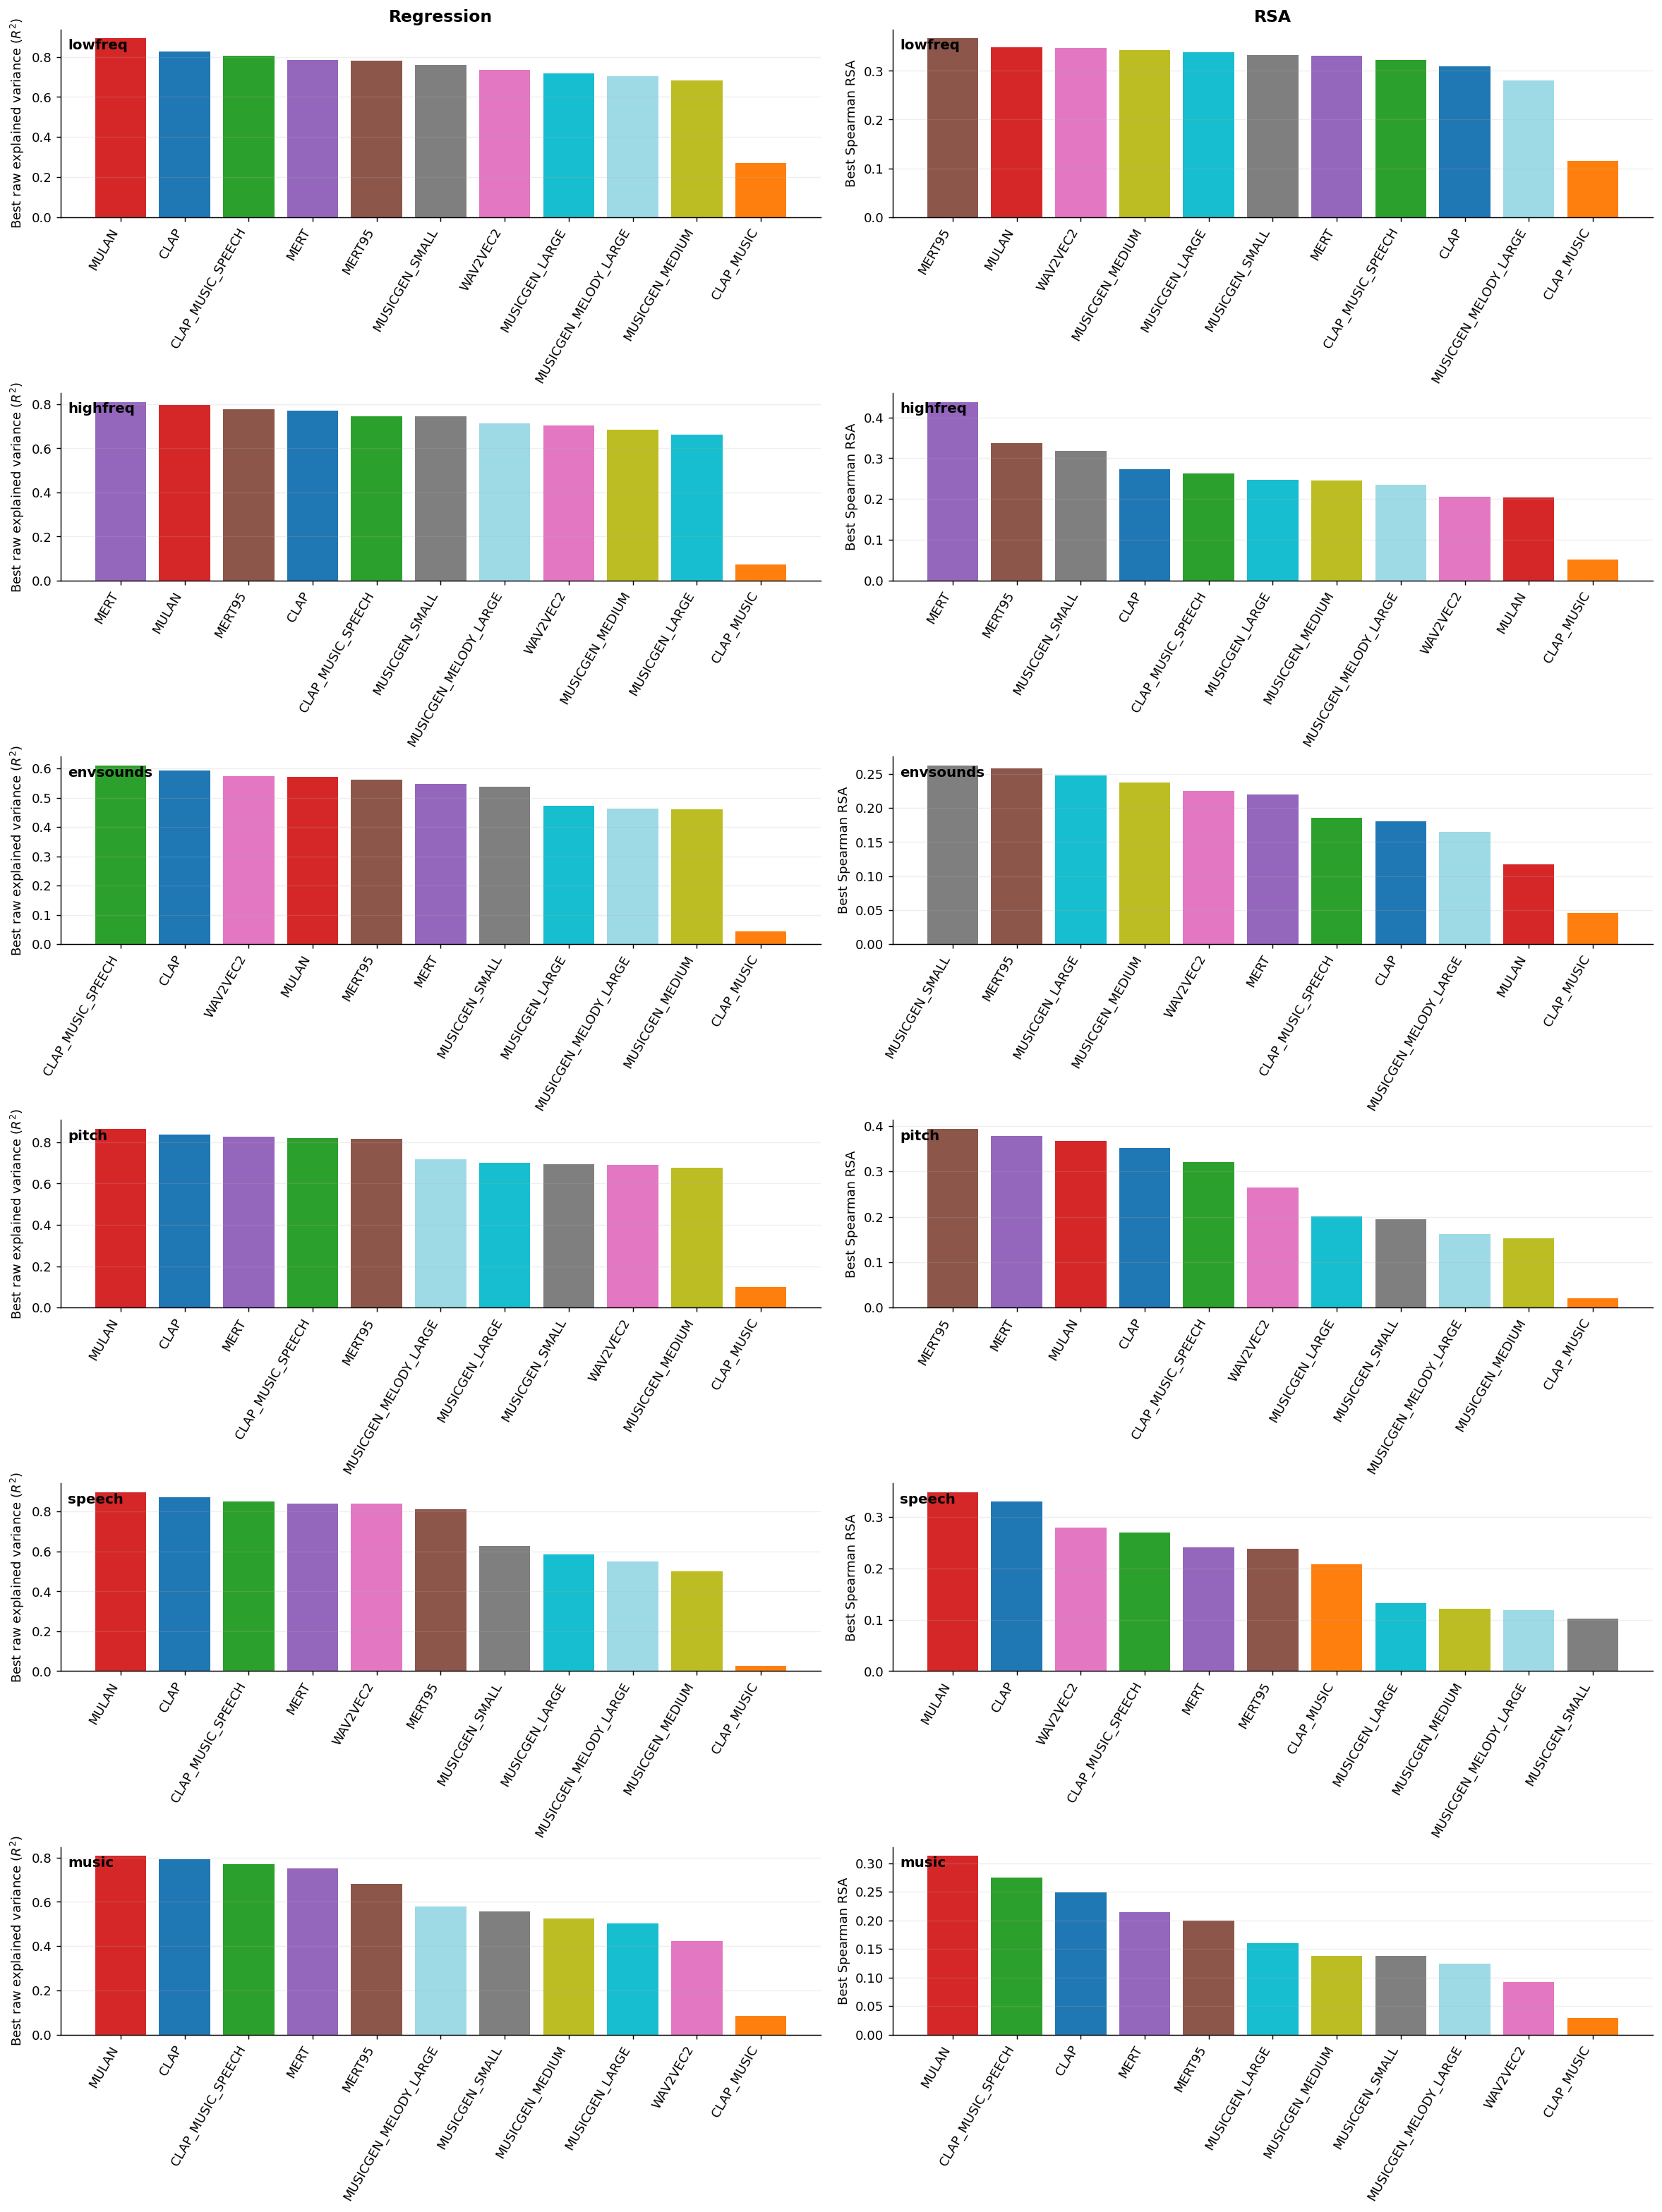

In [2]:
regression_all, rsa_all = refresh_component_summaries()
fig, axes = plot_best_alignment_panels(regression_all, rsa_all)
plt.show()

## 2. One Component Across All Models

Change `component_name` and rerun the cell.

In [3]:
# for component_name in COMPONENT_ORDER:
#     fig, axes = plot_component_layerwise_all_models(regression_all, rsa_all, component_name=component_name)
#     plt.show()
    
    
# # component_name = 'pitch'  # lowfreq, highfreq, envsounds, pitch, speech, music

# # regression_all, rsa_all = refresh_component_summaries()
# # fig, axes = plot_component_layerwise_all_models(regression_all, rsa_all, component_name=component_name)
# # plt.show()

## 3. One Model Across All Components

Change `model_name` and rerun the cell.

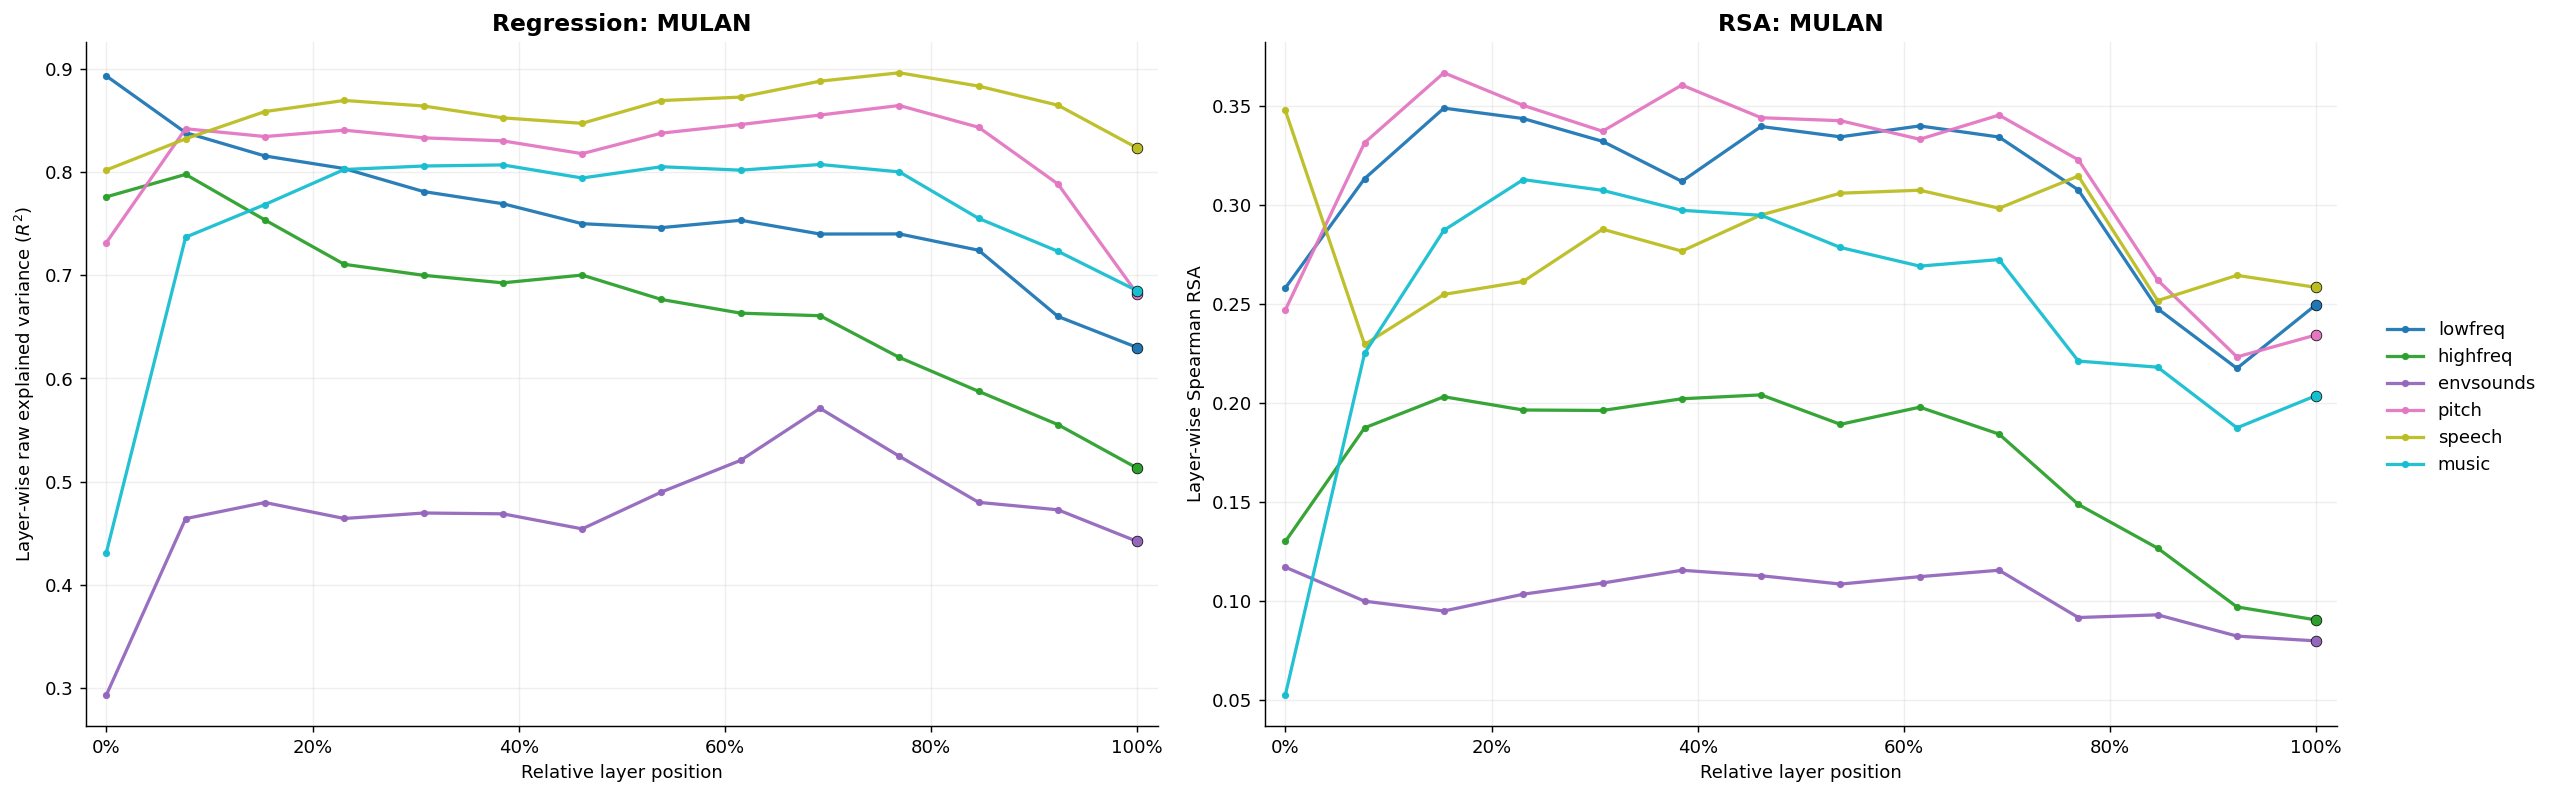

In [9]:
# # for model_name in ['CLAP', 'CLAP_MUSIC', 'CLAP_MUSIC_SPEECH', 'MULAN', 'MERT', 'MERT95', 'WAV2VEC2', 'MUSICGEN_SMALL', 'MUSICGEN_MEDIUM', 'MUSICGEN_LARGE', 'MUSICGEN_MELODY_LARGE']:
# #     regression_all, rsa_all = refresh_component_summaries()
# #     fig, axes = plot_model_layerwise_all_components(regression_all, rsa_all, model_name=model_name)
# #     plt.show()


# model_name = 'MULAN'  # CLAP, CLAP_MUSIC, CLAP_MUSIC_SPEECH, MULAN, MERT, MERT95, WAV2VEC2, MUSICGEN_SMALL, MUSICGEN_MEDIUM, MUSICGEN_LARGE, MUSICGEN_MELODY_LARGE

# regression_all, rsa_all = refresh_component_summaries()
# fig, axes = plot_model_layerwise_all_components(regression_all, rsa_all, model_name=model_name)
# plt.show()

## 4. Layer-Wise Brain-Task Correlation Heatmap (7 x 7)

Rows are brain alignment targets (`all_voxel` + 6 components), columns are downstream tasks (EMO split into `valence` and `arousal`).

You can choose:
- `correlation_method`: `pearson` or `spearman`
- `brain_alignment_kind`: `regression` or `rsa`

,emo_valence,emo_arousal,gtzan,giantsteps,magnatagatune,nsynthpitch5h,vocalset
all_voxel,0.162,0.418,0.531,0.259,0.636,0.303,0.650
lowfreq,0.140,0.353,0.475,0.264,0.582,0.329,0.607
highfreq,0.143,0.275,0.299,0.244,0.426,0.343,0.513
envsounds,-0.069,0.059,0.033,0.005,0.201,0.139,0.342
pitch,0.123,0.350,0.489,0.182,0.596,0.245,0.628
speech,-0.043,0.206,0.343,-0.036,0.419,0.000,0.452
music,0.279,0.442,0.569,0.328,0.697,0.363,0.727


,emo_valence,emo_arousal,gtzan,giantsteps,magnatagatune,nsynthpitch5h,vocalset
all_voxel,0.0099,0.000,0.0000,0.0000,0.0000,0.0000,0.0
lowfreq,0.0264,0.000,0.0000,0.0000,0.0000,0.0000,0.0
highfreq,0.0231,0.000,0.0000,0.0001,0.0000,0.0000,0.0
envsounds,0.2770,0.354,0.6013,0.9320,0.0013,0.0280,0.0
pitch,0.0511,0.000,0.0000,0.0038,0.0000,0.0001,0.0
speech,0.5025,0.001,0.0000,0.5671,0.0000,1.0000,0.0
music,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0


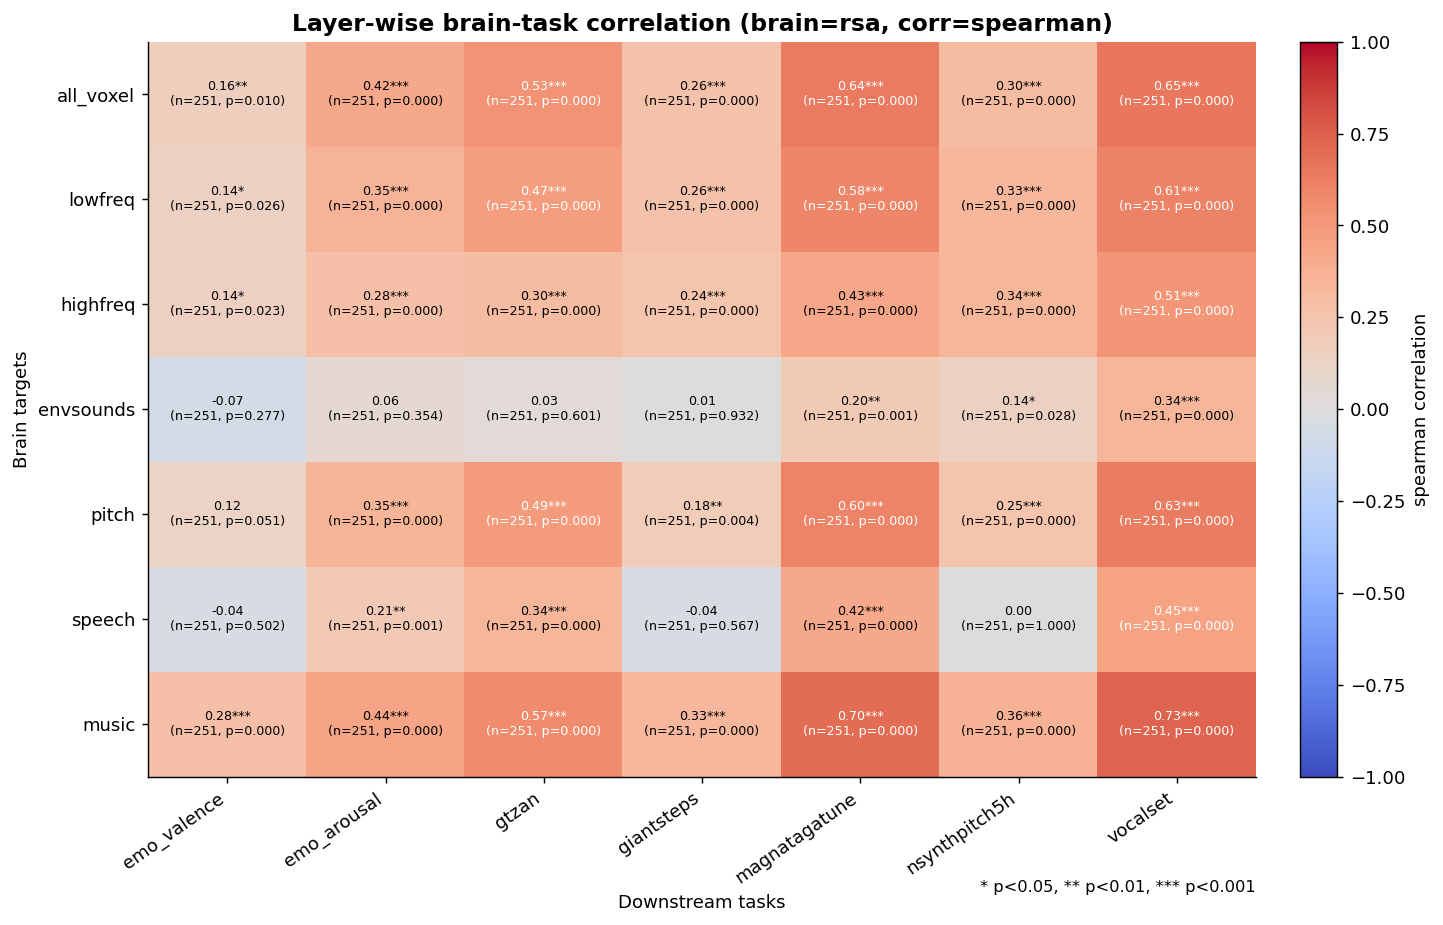

In [ ]:
# Configuration
correlation_method = 'spearman'    # 'pearson' or 'spearman'
brain_alignment_kind = 'rsa'  # 'regression' or 'rsa'

if correlation_method not in {'pearson', 'spearman'}:
    raise ValueError("correlation_method must be 'pearson' or 'spearman'")
if brain_alignment_kind not in {'regression', 'rsa'}:
    raise ValueError("brain_alignment_kind must be 'regression' or 'rsa'")

probe_layerwise_path = PROJECT_ROOT / 'music_task_probe' / 'probe_results_all_models' / 'probe_alignment_layerwise_merged.csv'
component_compiled_dir = PROJECT_ROOT / 'natural_component_align' / 'compiled_results'

component_metric_by_kind = {
    'regression': ('regression_layerwise_summary.csv', 'mean_r2'),
    'rsa': ('rsa_layerwise_summary.csv', 'mean_spearman'),
}

brain_rows = [
    ('all_voxel', 'all_voxel'),
    ('lowfreq', 'lowfreq'),
    ('highfreq', 'highfreq'),
    ('envsounds', 'envsounds'),
    ('pitch', 'pitch'),
    ('speech', 'speech'),
    ('music', 'music'),
]

task_specs = [
    ('emo_valence', 'EMO', 'emotion_regression', 'pearson_valence'),
    ('emo_arousal', 'EMO', 'emotion_regression', 'pearson_arousal'),
    ('gtzan', 'GTZAN', 'genre_classification', 'primary_metric_value'),
    ('giantsteps', 'GiantSteps', 'key_detection', 'primary_metric_value'),
    ('magnatagatune', 'MagnaTagATune', 'music_tagging', 'primary_metric_value'),
    ('nsynthpitch5h', 'NSynthPitch5h', 'pitch_estimation', 'primary_metric_value'),
    ('vocalset', 'VocalSet', 'singing_technique', 'primary_metric_value'),
]

from scipy.stats import pearsonr, spearmanr


def normalize_model_key(series):
    return series.astype(str).str.strip().str.upper()


def prepare_probe_layerwise(path, alignment_kind):
    df = pd.read_csv(path)
    df = df.copy()
    df['alignment_kind'] = df['alignment_kind'].astype(str).str.lower()
    df = df.loc[df['alignment_kind'] == alignment_kind].copy()

    if 'alignment_dataset' in df.columns:
        df = df.loc[df['alignment_dataset'].astype(str).str.lower() == 'mean'].copy()

    df['model_key'] = normalize_model_key(df['model_name'])
    df['layer_index'] = pd.to_numeric(df['layer_index'], errors='coerce')
    df['layer_depth'] = pd.to_numeric(df['layer_depth'], errors='coerce')
    df = df.dropna(subset=['model_key', 'layer_index', 'layer_depth'])

    return df


def prepare_component_layerwise(compiled_dir, alignment_kind):
    file_name, metric_col = component_metric_by_kind[alignment_kind]
    df = pd.read_csv(compiled_dir / file_name)
    df = df.copy()

    df['model_key'] = normalize_model_key(df['model_name'])
    df['layer_index'] = pd.to_numeric(df['layer_index'], errors='coerce')
    df['layer_depth'] = pd.to_numeric(df['layer_depth'], errors='coerce')
    df['component_name'] = df['component_name'].astype(str).str.lower()
    df['brain_score'] = pd.to_numeric(df[metric_col], errors='coerce')

    df = (
        df[['model_key', 'layer_index', 'layer_depth', 'component_name', 'brain_score']]
        .dropna(subset=['model_key', 'layer_index', 'layer_depth', 'component_name', 'brain_score'])
        .groupby(['model_key', 'layer_index', 'layer_depth', 'component_name'], as_index=False)['brain_score']
        .mean()
    )
    return df


def build_brain_series_map(probe_df, component_df):
    all_voxel = (
        probe_df[['model_key', 'layer_depth', 'alignment_score']]
        .rename(columns={'alignment_score': 'brain_score'})
        .dropna(subset=['brain_score'])
        .groupby(['model_key', 'layer_depth'], as_index=False)['brain_score']
        .mean()
    )

    brain_map = {'all_voxel': all_voxel}
    for comp in ['lowfreq', 'highfreq', 'envsounds', 'pitch', 'speech', 'music']:
        comp_df = component_df.loc[component_df['component_name'] == comp, ['model_key', 'layer_depth', 'brain_score']].copy()
        comp_df = comp_df.groupby(['model_key', 'layer_depth'], as_index=False)['brain_score'].mean()
        brain_map[comp] = comp_df

    return brain_map


def build_task_series_map(probe_df):
    task_map = {}
    for task_label, dataset_name, task_name, metric_col in task_specs:
        subset = probe_df.loc[
            (probe_df['dataset_name'] == dataset_name) &
            (probe_df['task_name'] == task_name),
            ['model_key', 'layer_depth', metric_col]
        ].copy()

        subset['task_score'] = pd.to_numeric(subset[metric_col], errors='coerce')
        subset = (
            subset[['model_key', 'layer_depth', 'task_score']]
            .dropna(subset=['task_score'])
            .groupby(['model_key', 'layer_depth'], as_index=False)['task_score']
            .mean()
        )
        task_map[task_label] = subset

    return task_map


def compute_brain_task_correlation(brain_df, task_df, method='pearson'):
    merged = brain_df.merge(task_df, on=['model_key', 'layer_depth'], how='inner')
    merged = merged[['brain_score', 'task_score']].dropna()
    n_points = len(merged)
    if n_points < 3:
        return np.nan, np.nan, n_points

    x = merged['brain_score'].to_numpy()
    y = merged['task_score'].to_numpy()

    if method == 'pearson':
        corr_value, p_value = pearsonr(x, y)
    elif method == 'spearman':
        corr_value, p_value = spearmanr(x, y)
    else:
        raise ValueError(f'Unsupported correlation method: {method}')

    return float(corr_value), float(p_value), n_points


def significance_stars(p_value):
    if np.isnan(p_value):
        return ''
    if p_value < 0.001:
        return '***'
    if p_value < 0.01:
        return '**'
    if p_value < 0.05:
        return '*'
    return ''


def build_correlation_matrices(brain_map, task_map, corr_method):
    row_labels = [row_label for row_label, _ in brain_rows]
    col_labels = [task_label for task_label, _, _, _ in task_specs]

    corr_matrix = pd.DataFrame(np.nan, index=row_labels, columns=col_labels)
    p_matrix = pd.DataFrame(np.nan, index=row_labels, columns=col_labels)
    n_matrix = pd.DataFrame(0, index=row_labels, columns=col_labels, dtype=int)

    for row_label, brain_key in brain_rows:
        for task_label in col_labels:
            corr_value, p_value, n_points = compute_brain_task_correlation(
                brain_map[brain_key],
                task_map[task_label],
                method=corr_method,
            )
            corr_matrix.loc[row_label, task_label] = corr_value
            p_matrix.loc[row_label, task_label] = p_value
            n_matrix.loc[row_label, task_label] = int(n_points)

    return corr_matrix, p_matrix, n_matrix


def plot_correlation_heatmap(corr_matrix, p_matrix, n_matrix, corr_method, alignment_kind):
    fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)

    im = ax.imshow(corr_matrix.to_numpy(), cmap='coolwarm', vmin=-1.0, vmax=1.0, aspect='auto')

    ax.set_xticks(np.arange(len(corr_matrix.columns)))™
    ax.set_xticklabels(corr_matrix.columns, rotation=35, ha='right')
    ax.set_yticks(np.arange(len(corr_matrix.index)))
    ax.set_yticklabels(corr_matrix.index)

    for i in range(corr_matrix.shape[0]):
        for j in range(corr_matrix.shape[1]):
            value = corr_matrix.iat[i, j]
            p_value = p_matrix.iat[i, j]
            n_points = n_matrix.iat[i, j]

            if np.isnan(value):
                text = f'nan\n(n={n_points})'
                color = 'black'
            else:
                stars = significance_stars(p_value)
                if np.isnan(p_value):
                    p_text = 'p=n/a'
                else:
                    p_text = f'p={p_value:.3f}'
                text = f'{value:.2f}{stars}\n(n={n_points}, {p_text})'
                color = 'white' if abs(value) > 0.45 else 'black'
            ax.text(j, i, text, ha='center', va='center', fontsize=7, color=color)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(f'{corr_method} correlation', rotation=90)

    ax.set_title(
        f'Layer-wise brain-task correlation (brain={alignment_kind}, corr={corr_method})',
        fontsize=13,
        fontweight='bold',
    )
    ax.set_xlabel('Downstream tasks')
    ax.set_ylabel('Brain targets')
    ax.text(
        1.0,
        -0.14,
        '* p<0.05, ** p<0.01, *** p<0.001',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=9,
    )

    return fig, ax


probe_layerwise = prepare_probe_layerwise(probe_layerwise_path, brain_alignment_kind)
component_layerwise = prepare_component_layerwise(component_compiled_dir, brain_alignment_kind)

brain_series_map = build_brain_series_map(probe_layerwise, component_layerwise)
task_series_map = build_task_series_map(probe_layerwise)

corr_matrix, p_matrix, n_matrix = build_correlation_matrices(brain_series_map, task_series_map, correlation_method)

display(corr_matrix.round(3))
display(p_matrix.round(4))
fig, ax = plot_correlation_heatmap(corr_matrix, p_matrix, n_matrix, correlation_method, brain_alignment_kind)
plt.show()

In [26]:
# 4-c. Export corr_matrix.round(3) to LaTeX table (column-wise max in bold)
from pathlib import Path

rounded_corr = corr_matrix.round(3).copy()
formatted_corr = rounded_corr.copy()

for col in formatted_corr.columns:
    col_max = rounded_corr[col].max(skipna=True)

    def _fmt_cell(v, max_v=col_max):
        if pd.isna(v):
            return '--'
        text = f'{v:.3f}'
        if pd.notna(max_v) and np.isclose(v, max_v, atol=5e-4):
            return f'\\textbf{{{text}}}'
        return text

    formatted_corr[col] = rounded_corr[col].map(_fmt_cell)

table_caption = (
    f'Layer-wise brain-task correlation matrix (brain={brain_alignment_kind}, corr={correlation_method}). '
    'Column-wise maxima are boldfaced.'
)
table_label = f'tab:corr-matrix-{brain_alignment_kind}-{correlation_method}'

latex_table = formatted_corr.to_latex(
    escape=False,
    index=True,
    column_format='l' + 'c' * len(formatted_corr.columns),
    caption=table_caption,
    label=table_label,
    na_rep='--',
)

output_path = PROJECT_ROOT / 'tex' / 'corr_matrix.tex'
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(latex_table, encoding='utf-8')

print(f'LaTeX table written to: {output_path}')
display(formatted_corr)

LaTeX table written to: /home/hjkim/selective_auditory/ismir2026/tex/corr_matrix.tex


,emo_valence,emo_arousal,gtzan,giantsteps,magnatagatune,nsynthpitch5h,vocalset
all_voxel,0.162,0.418,0.531,0.259,0.636,0.303,0.650
lowfreq,0.140,0.353,0.475,0.264,0.582,0.329,0.607
highfreq,0.143,0.275,0.299,0.244,0.426,0.343,0.513
envsounds,-0.069,0.059,0.033,0.005,0.201,0.139,0.342
pitch,0.123,0.350,0.489,0.182,0.596,0.245,0.628
speech,-0.043,0.206,0.343,-0.036,0.419,0.000,0.452
music,\textbf{0.279},\textbf{0.442},\textbf{0.569},\textbf{0.328},\textbf{0.697},\textbf{0.363},\textbf{0.727}


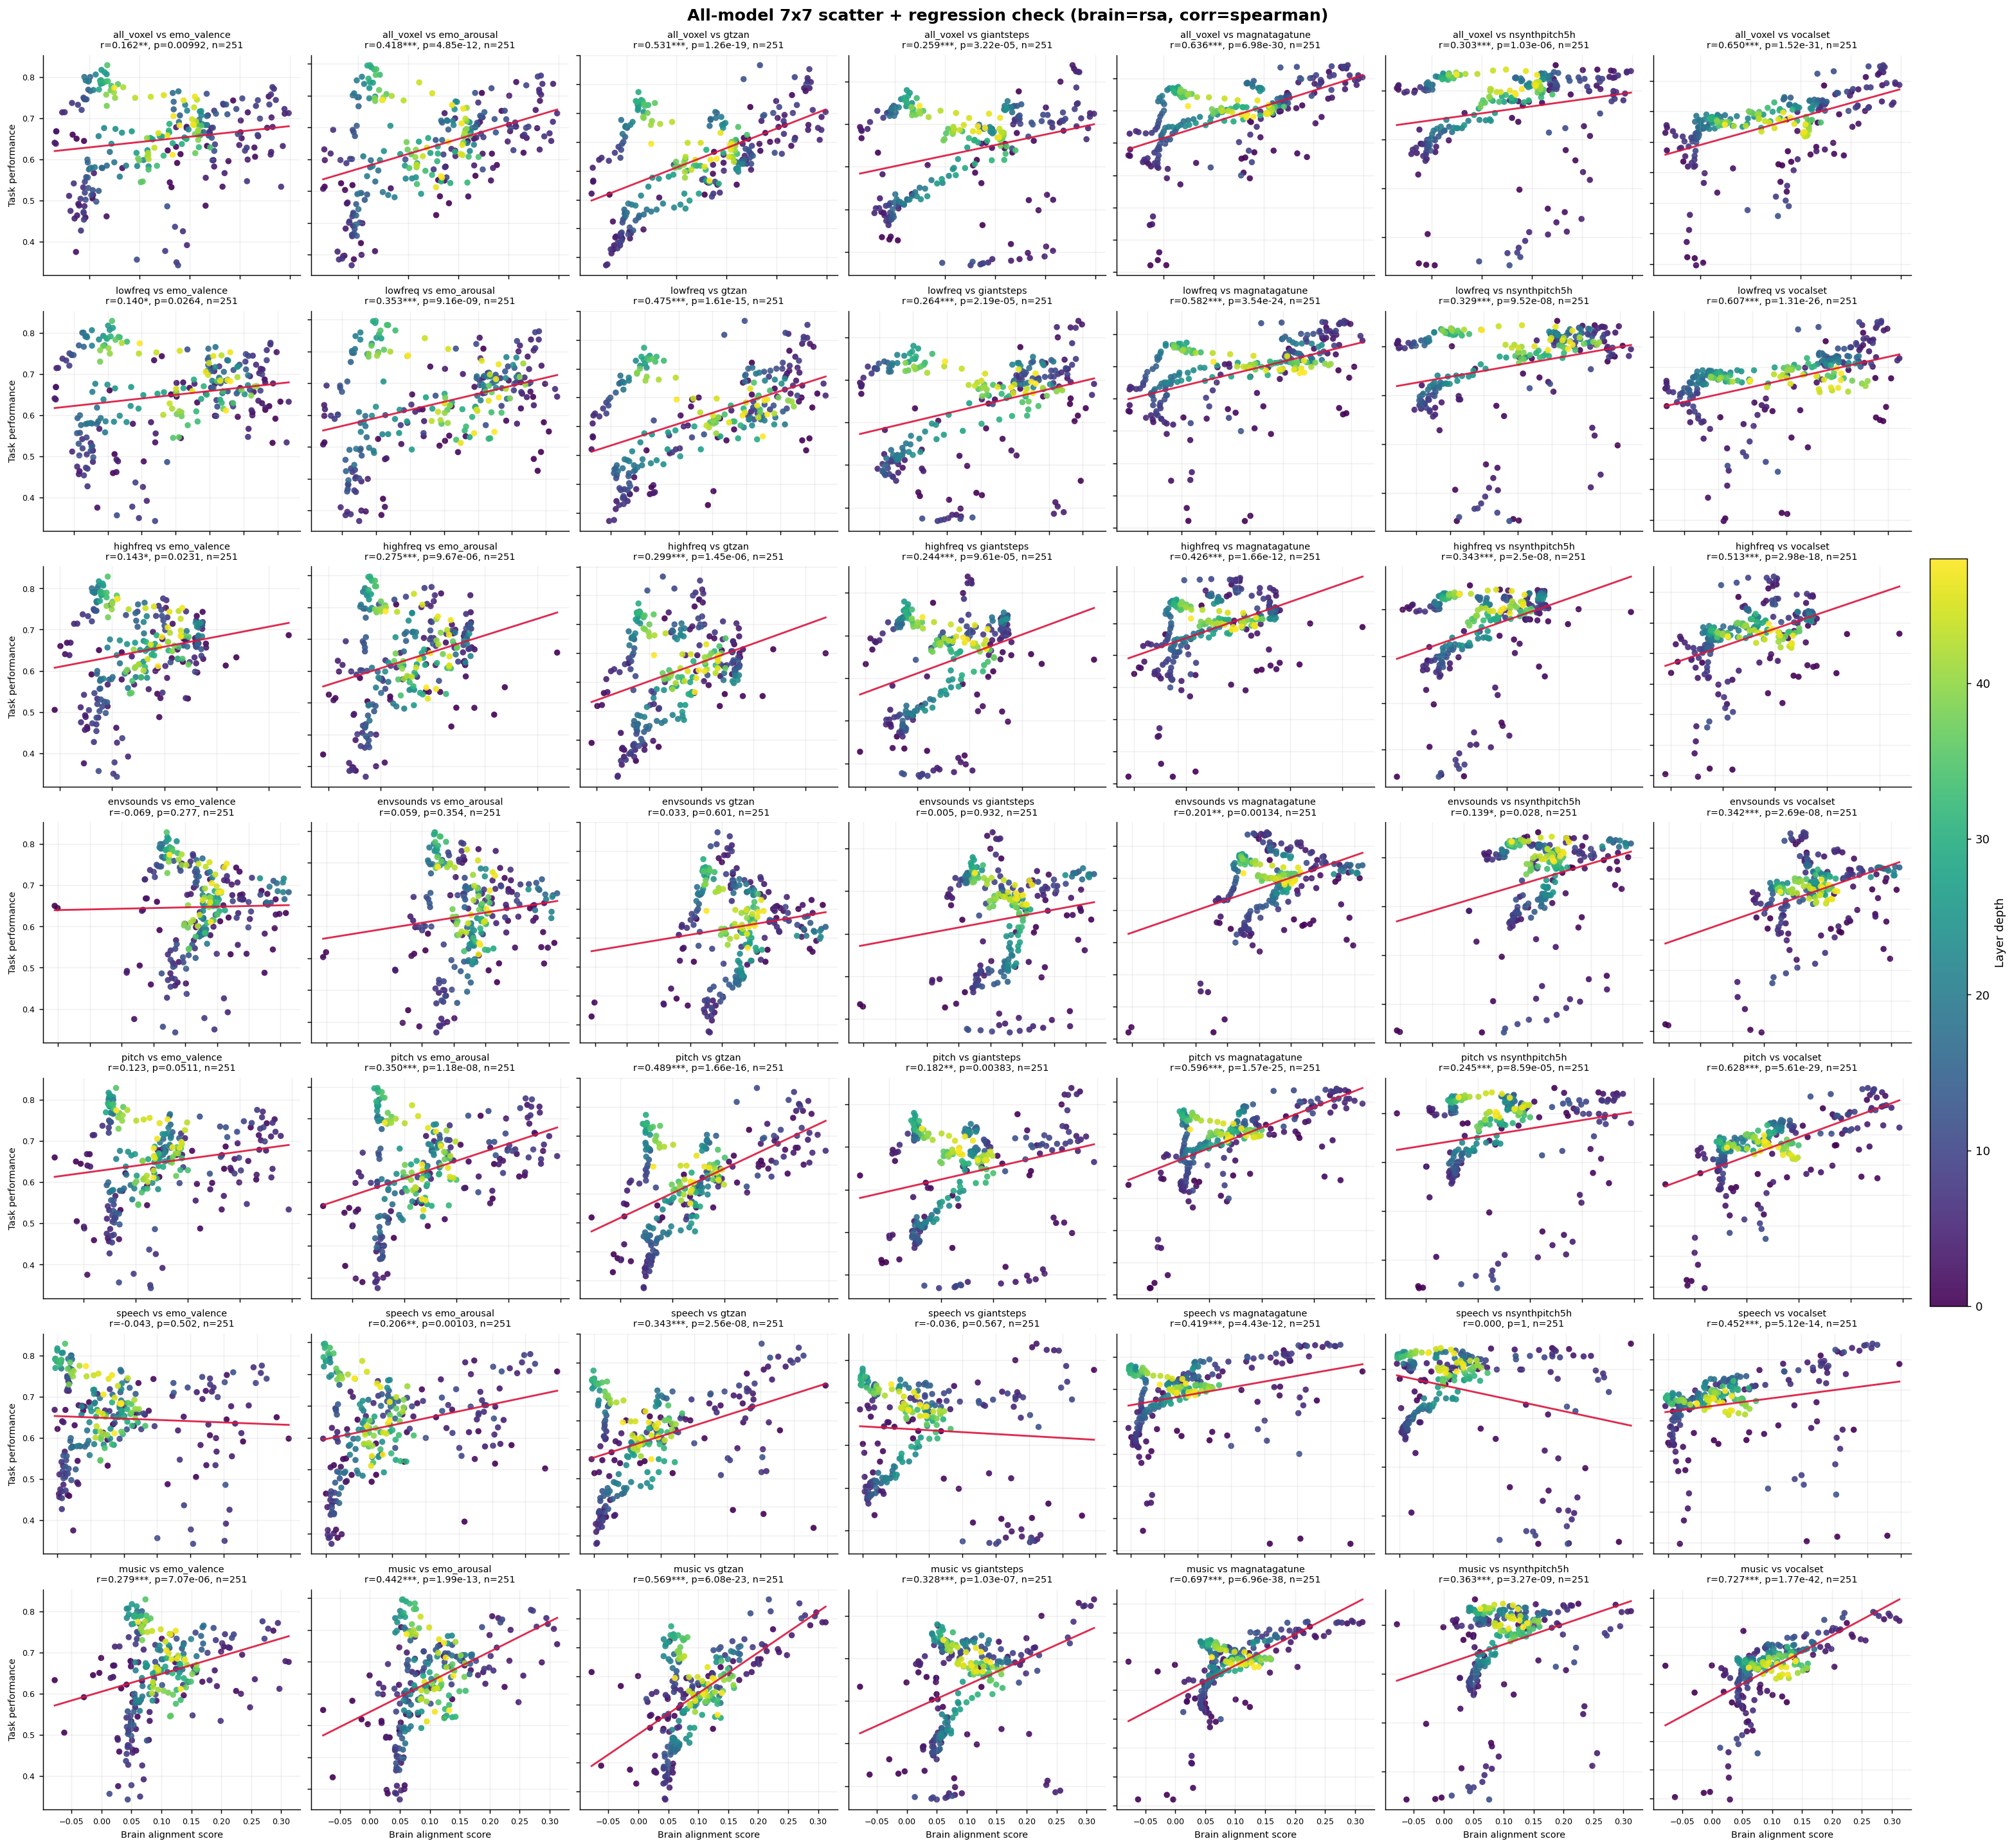

In [20]:
# 4-b. All-model 7x7 scatter grid (matches heatmap cells)
row_labels = [row_label for row_label, _ in brain_rows]
col_labels = [task_label for task_label, _, _, _ in task_specs]

fig, axes = plt.subplots(
    len(row_labels),
    len(col_labels),
    figsize=(24, 22),
    constrained_layout=True,
    sharex=False,
    sharey=False,
    squeeze=False,
)

last_sc = None

for i, row_label in enumerate(row_labels):
    for j, task_label in enumerate(col_labels):
        ax = axes[i, j]

        brain_df = brain_series_map[row_label].copy()
        task_df = task_series_map[task_label].copy()

        merged = brain_df.merge(task_df, on=['model_key', 'layer_depth'], how='inner')
        merged = merged[['layer_depth', 'brain_score', 'task_score']].dropna().sort_values('layer_depth')
        n_points = len(merged)

        if n_points == 0:
            ax.set_axis_off()
            continue

        # Scatter points; color shows layer depth progression.
        sc = ax.scatter(
            merged['brain_score'],
            merged['task_score'],
            c=merged['layer_depth'],
            cmap='viridis',
            s=28,
            alpha=0.9,
            edgecolor='none',
        )
        last_sc = sc

        corr_value, p_value, n_corr = compute_brain_task_correlation(
            brain_df,
            task_df,
            method=correlation_method,
)

        # OLS trend line for visual check against the correlation value.
        if n_points >= 2 and merged['brain_score'].nunique() >= 2:
            x = merged['brain_score'].to_numpy()
            y = merged['task_score'].to_numpy()
            slope, intercept = np.polyfit(x, y, 1)
            x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
            y_line = slope * x_line + intercept
            ax.plot(x_line, y_line, color='crimson', linewidth=1.6, alpha=0.9)

        stars = significance_stars(p_value)
        if np.isnan(corr_value):
            title_text = f'{row_label} vs {task_label}\nr=nan, p=nan, n={n_corr}'
        else:
            title_text = f'{row_label} vs {task_label}\nr={corr_value:.3f}{stars}, p={p_value:.3g}, n={n_corr}'
        ax.set_title(title_text, fontsize=8)

        if i == len(row_labels) - 1:
            ax.set_xlabel('Brain alignment score', fontsize=8)
        else:
            ax.set_xticklabels([])

        if j == 0:
            ax.set_ylabel('Task performance', fontsize=8)
        else:
            ax.set_yticklabels([])

        ax.tick_params(axis='both', labelsize=7)
        ax.grid(alpha=0.2)

fig.suptitle(
    f'All-model 7x7 scatter + regression check (brain={brain_alignment_kind}, corr={correlation_method})',
    fontsize=14,
    fontweight='bold',
)

if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=axes, fraction=0.02, pad=0.01)
    cbar.set_label('Layer depth')

plt.show()

## 5. Layer-Wise Brain-Task Correlation Heatmap For One Model (7 x 7)

Filter the same correlation analysis to a single model.

Change `selected_model_name` and rerun the cell.


,emo_valence,emo_arousal,gtzan,giantsteps,magnatagatune,nsynthpitch5h,vocalset
all_voxel,0.6,1.0,0.5,0.5,0.3,0.9,0.5
lowfreq,-0.5,0.3,0.9,-0.6,0.8,-0.1,0.9
highfreq,0.9,0.7,0.1,0.6,0.0,0.9,0.1
envsounds,0.7,0.5,0.0,0.5,0.1,0.8,0.0
pitch,0.9,0.7,0.1,0.6,0.0,0.9,0.1
speech,-0.8,-0.6,-0.3,-0.3,-0.1,-0.7,-0.3
music,-0.4,0.3,0.9,-0.6,1.0,0.1,0.9


,emo_valence,emo_arousal,gtzan,giantsteps,magnatagatune,nsynthpitch5h,vocalset
all_voxel,0.2848,0.0000,0.3910,0.3910,0.6238,0.0374,0.3910
lowfreq,0.3910,0.6238,0.0374,0.2848,0.1041,0.8729,0.0374
highfreq,0.0374,0.1881,0.8729,0.2848,1.0000,0.0374,0.8729
envsounds,0.1881,0.3910,1.0000,0.3910,0.8729,0.1041,1.0000
pitch,0.0374,0.1881,0.8729,0.2848,1.0000,0.0374,0.8729
speech,0.1041,0.2848,0.6238,0.6238,0.8729,0.1881,0.6238
music,0.5046,0.6238,0.0374,0.2848,0.0000,0.8729,0.0374


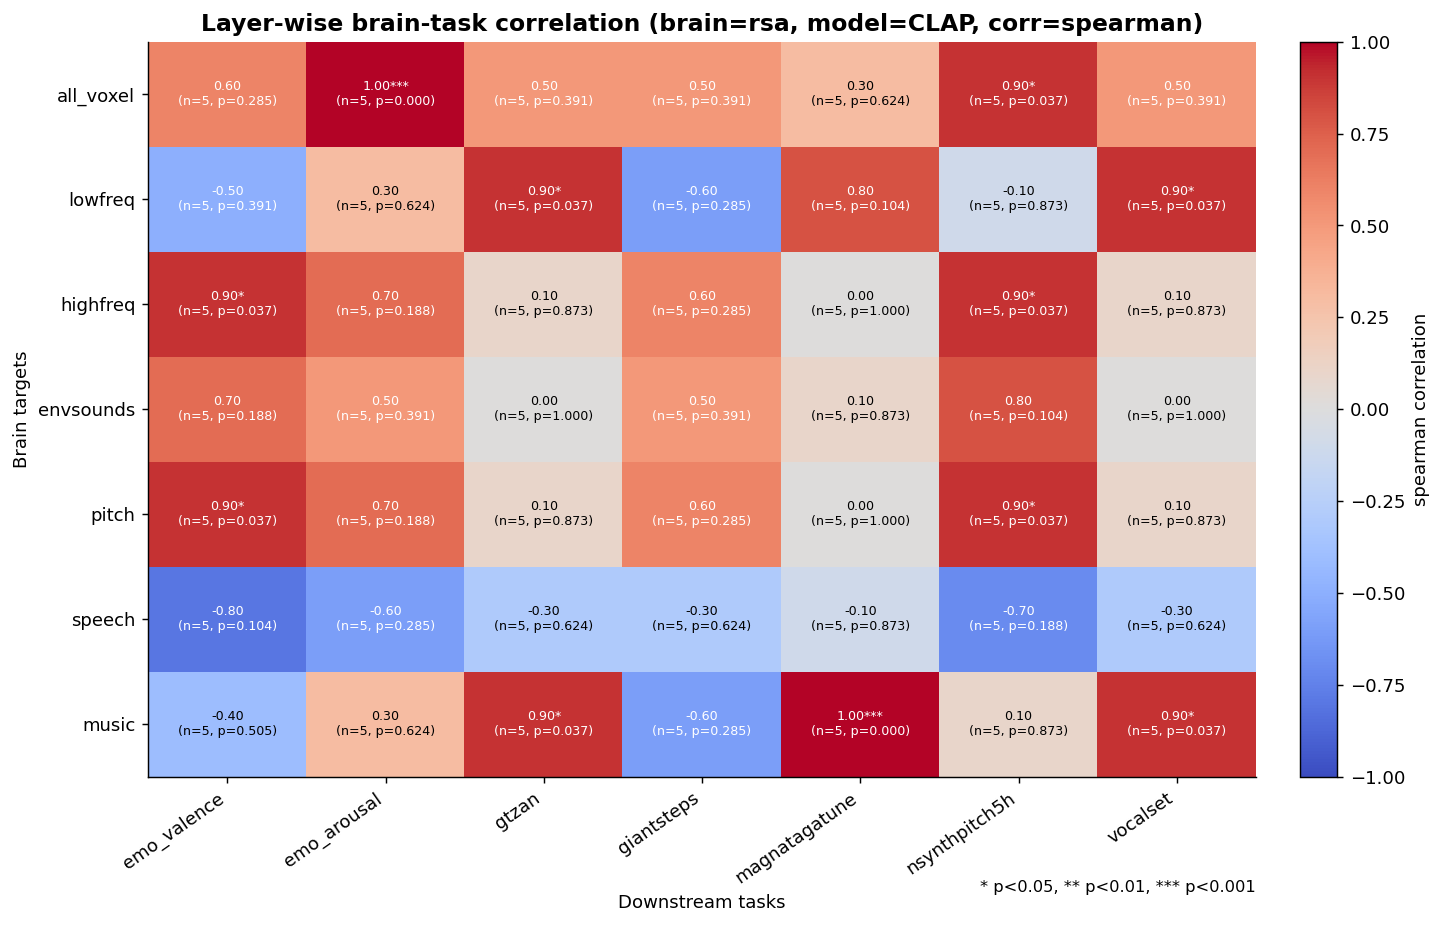

In [22]:
selected_model_name = 'CLAP'  # CLAP, CLAP_MUSIC, CLAP_MUSIC_SPEECH, MULAN, MERT, MERT95, WAV2VEC2, MUSICGEN_SMALL, MUSICGEN_MEDIUM, MUSICGEN_LARGE, MUSICGEN_MELODY_LARGE

selected_model_key = str(selected_model_name).strip().upper()
if selected_model_key not in {str(model).strip().upper() for model in MODEL_ORDER}:
    raise ValueError(f'Unsupported model_name: {selected_model_name}')

probe_layerwise_single = probe_layerwise.loc[probe_layerwise['model_key'] == selected_model_key].copy()
component_layerwise_single = component_layerwise.loc[component_layerwise['model_key'] == selected_model_key].copy()

if probe_layerwise_single.empty:
    raise RuntimeError(f'No probe rows found for model {selected_model_key}')
if component_layerwise_single.empty:
    raise RuntimeError(f'No component rows found for model {selected_model_key}')

brain_series_map_single = build_brain_series_map(probe_layerwise_single, component_layerwise_single)
task_series_map_single = build_task_series_map(probe_layerwise_single)

corr_matrix_single, p_matrix_single, n_matrix_single = build_correlation_matrices(
    brain_series_map_single,
    task_series_map_single,
    correlation_method,
)

display(corr_matrix_single.round(3))
display(p_matrix_single.round(4))
fig, ax = plot_correlation_heatmap(
    corr_matrix_single,
    p_matrix_single,
    n_matrix_single,
    correlation_method,
    f'{brain_alignment_kind}, model={selected_model_key}',
)
plt.show()


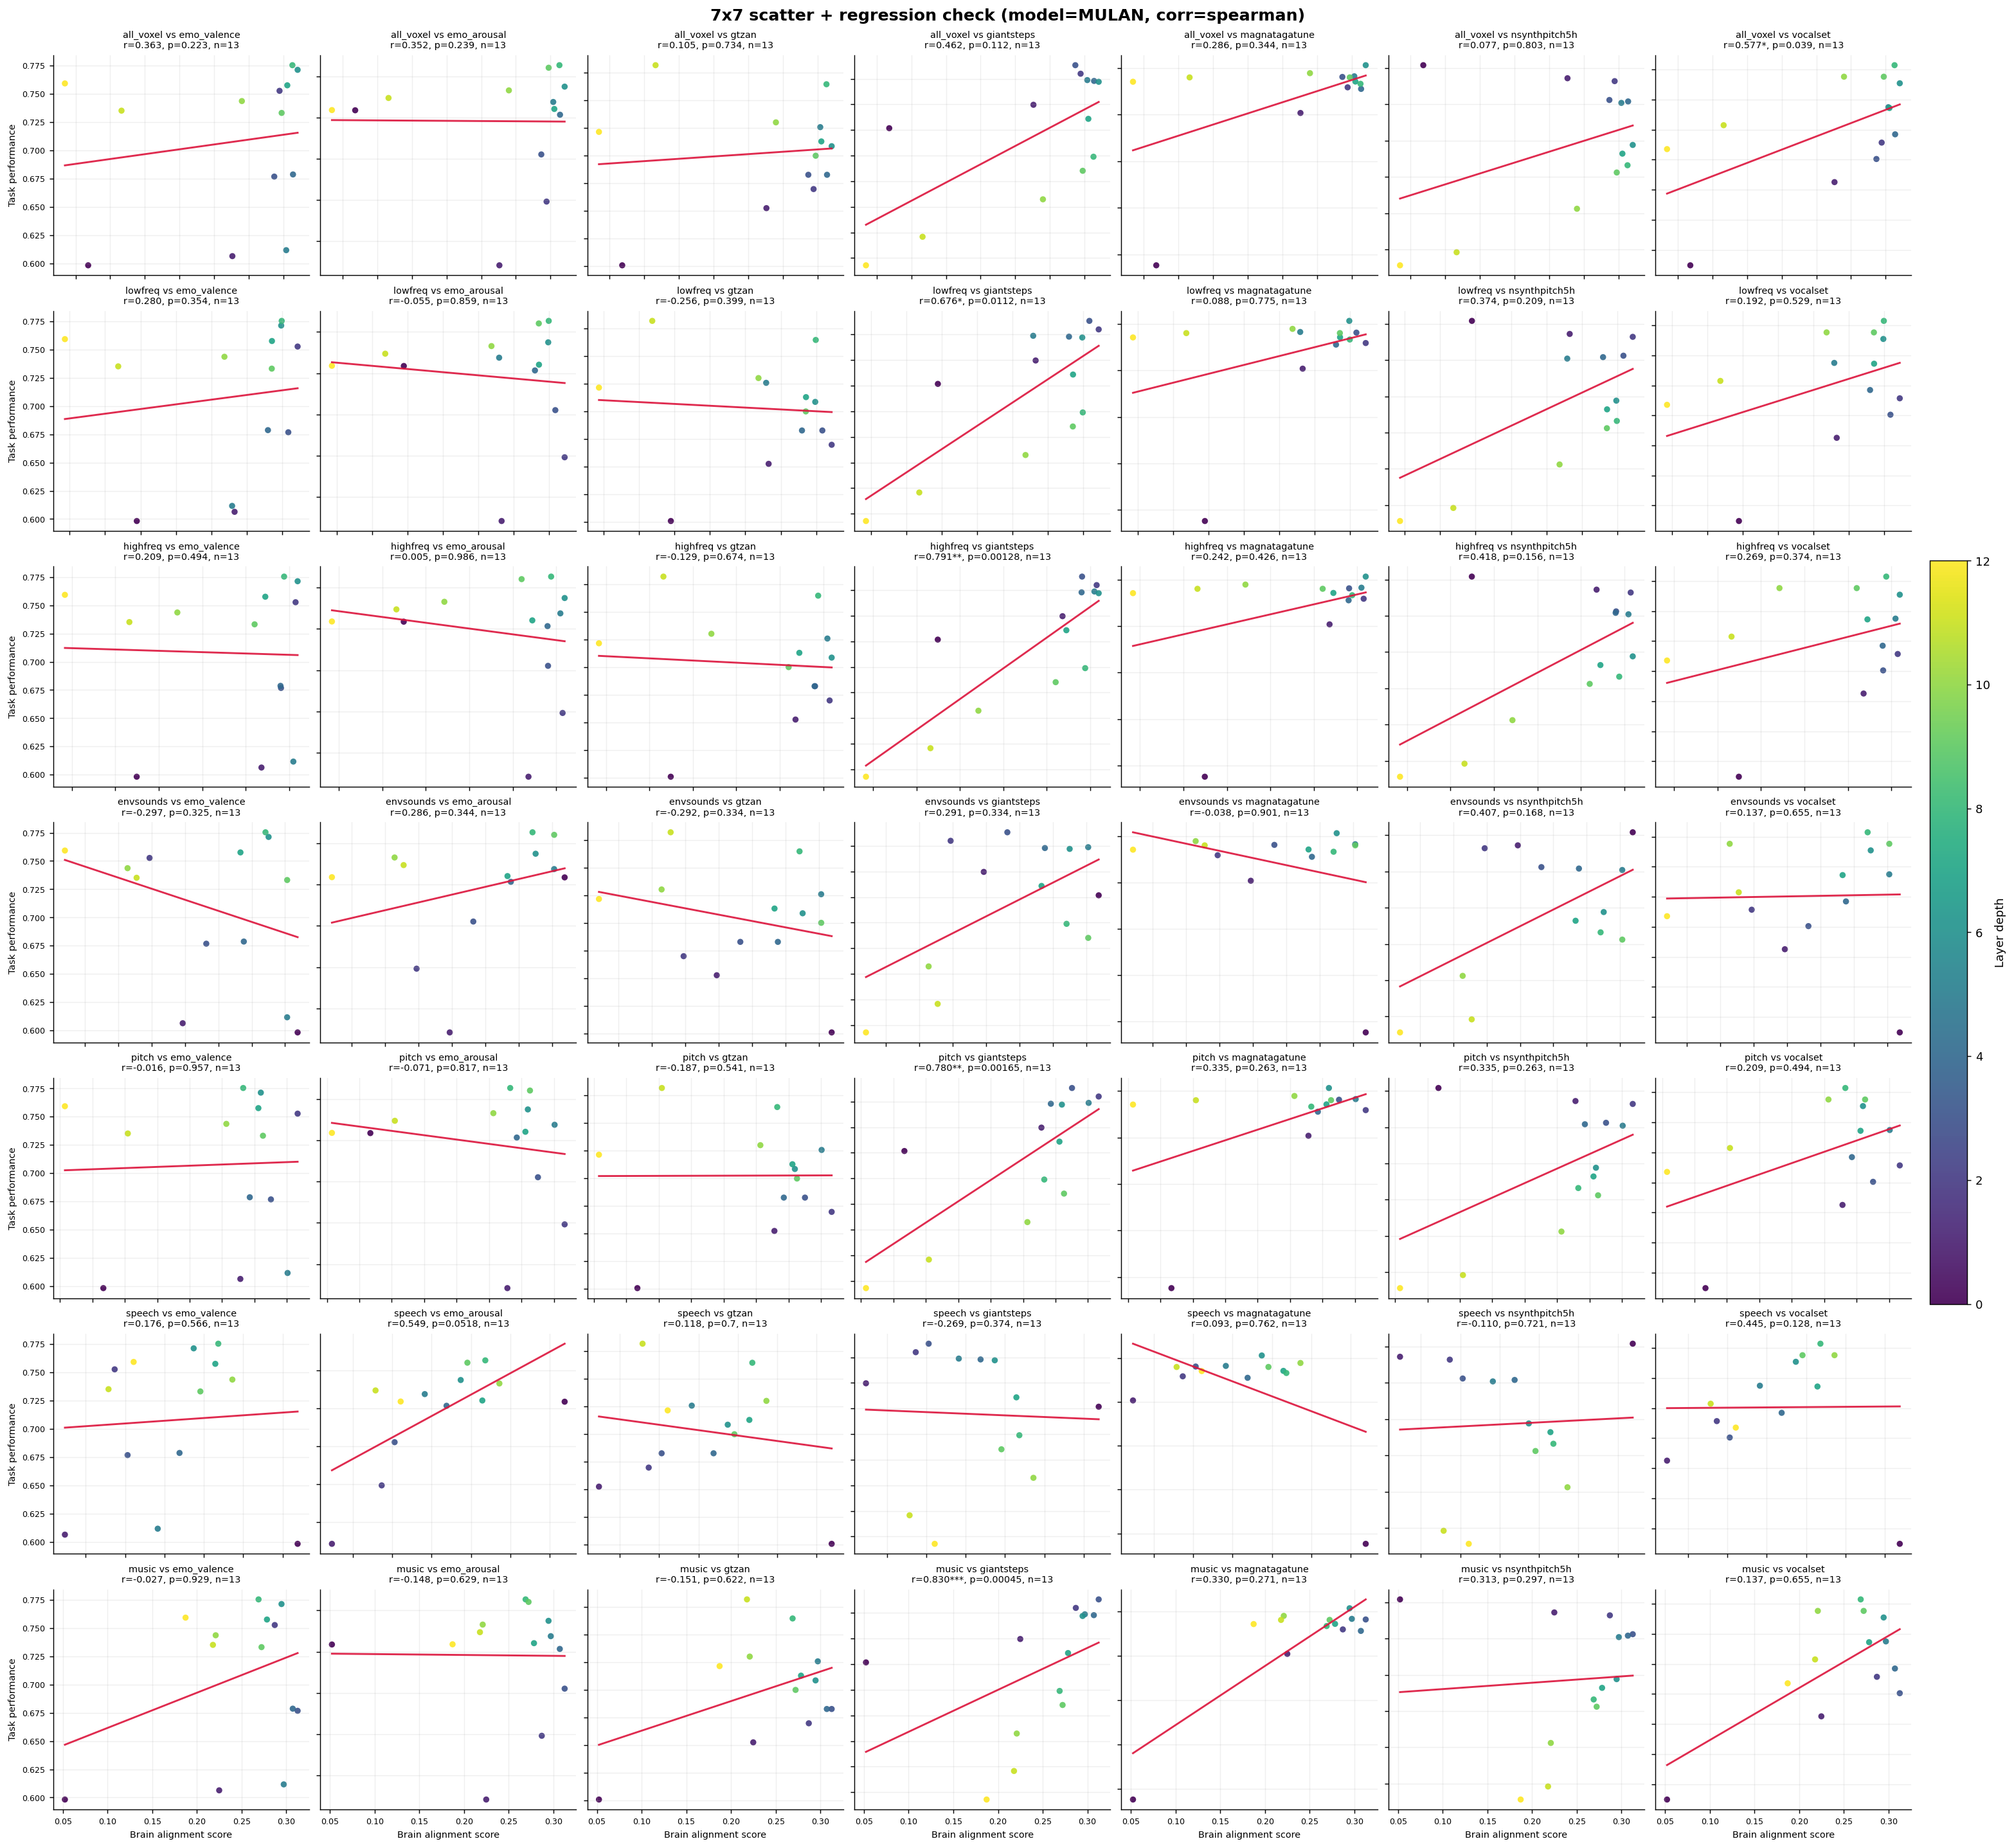

In [23]:
# 5-b. One-model 7x7 scatter grid (matches heatmap cells)
selected_model_name = 'MULAN'  # set model to inspect
selected_model_key = str(selected_model_name).strip().upper()

if selected_model_key not in {str(model).strip().upper() for model in MODEL_ORDER}:
    raise ValueError(f'Unsupported model_name: {selected_model_name}')

# Use the same filtered data basis as the one-model heatmap
probe_layerwise_single = probe_layerwise.loc[probe_layerwise['model_key'] == selected_model_key].copy()
component_layerwise_single = component_layerwise.loc[component_layerwise['model_key'] == selected_model_key].copy()

if probe_layerwise_single.empty:
    raise RuntimeError(f'No probe rows found for model {selected_model_key}')
if component_layerwise_single.empty:
    raise RuntimeError(f'No component rows found for model {selected_model_key}')

brain_series_map_single = build_brain_series_map(probe_layerwise_single, component_layerwise_single)
task_series_map_single = build_task_series_map(probe_layerwise_single)

row_labels = [row_label for row_label, _ in brain_rows]
col_labels = [task_label for task_label, _, _, _ in task_specs]

fig, axes = plt.subplots(
    len(row_labels),
    len(col_labels),
    figsize=(24, 22),
    constrained_layout=True,
    sharex=False,
    sharey=False,
    squeeze=False,
 )

for i, row_label in enumerate(row_labels):
    for j, task_label in enumerate(col_labels):
        ax = axes[i, j]

        brain_df = brain_series_map_single[row_label].copy()
        task_df = task_series_map_single[task_label].copy()

        merged = brain_df.merge(task_df, on=['model_key', 'layer_depth'], how='inner')
        merged = merged[['layer_depth', 'brain_score', 'task_score']].dropna().sort_values('layer_depth')
        n_points = len(merged)

        if n_points == 0:
            ax.set_axis_off()
            continue

        # Scatter points (colored by layer depth to track progression)
        sc = ax.scatter(
            merged['brain_score'],
            merged['task_score'],
            c=merged['layer_depth'],
            cmap='viridis',
            s=28,
            alpha=0.9,
            edgecolor='none',
        )

        # Compute the same correlation used in heatmap cells
        corr_value, p_value, n_corr = compute_brain_task_correlation(
            brain_df,
            task_df,
            method=correlation_method,
        )

        # Draw OLS regression line for visual trend check
        if n_points >= 2 and merged['brain_score'].nunique() >= 2:
            x = merged['brain_score'].to_numpy()
            y = merged['task_score'].to_numpy()
            slope, intercept = np.polyfit(x, y, 1)
            x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
            y_line = slope * x_line + intercept
            ax.plot(x_line, y_line, color='crimson', linewidth=1.6, alpha=0.9)

        stars = significance_stars(p_value)
        if np.isnan(corr_value):
            title_text = f'{row_label} vs {task_label}\nr=nan, p=nan, n={n_corr}'
        else:
            title_text = f'{row_label} vs {task_label}\nr={corr_value:.3f}{stars}, p={p_value:.3g}, n={n_corr}'
        ax.set_title(title_text, fontsize=8)

        if i == len(row_labels) - 1:
            ax.set_xlabel('Brain alignment score', fontsize=8)
        else:
            ax.set_xticklabels([])

        if j == 0:
            ax.set_ylabel('Task performance', fontsize=8)
        else:
            ax.set_yticklabels([])

        ax.tick_params(axis='both', labelsize=7)
        ax.grid(alpha=0.2)

fig.suptitle(
    f'7x7 scatter + regression check (model={selected_model_key}, corr={correlation_method})',
    fontsize=14,
    fontweight='bold',
)

cbar = fig.colorbar(sc, ax=axes, fraction=0.02, pad=0.01)
cbar.set_label('Layer depth')

plt.show()

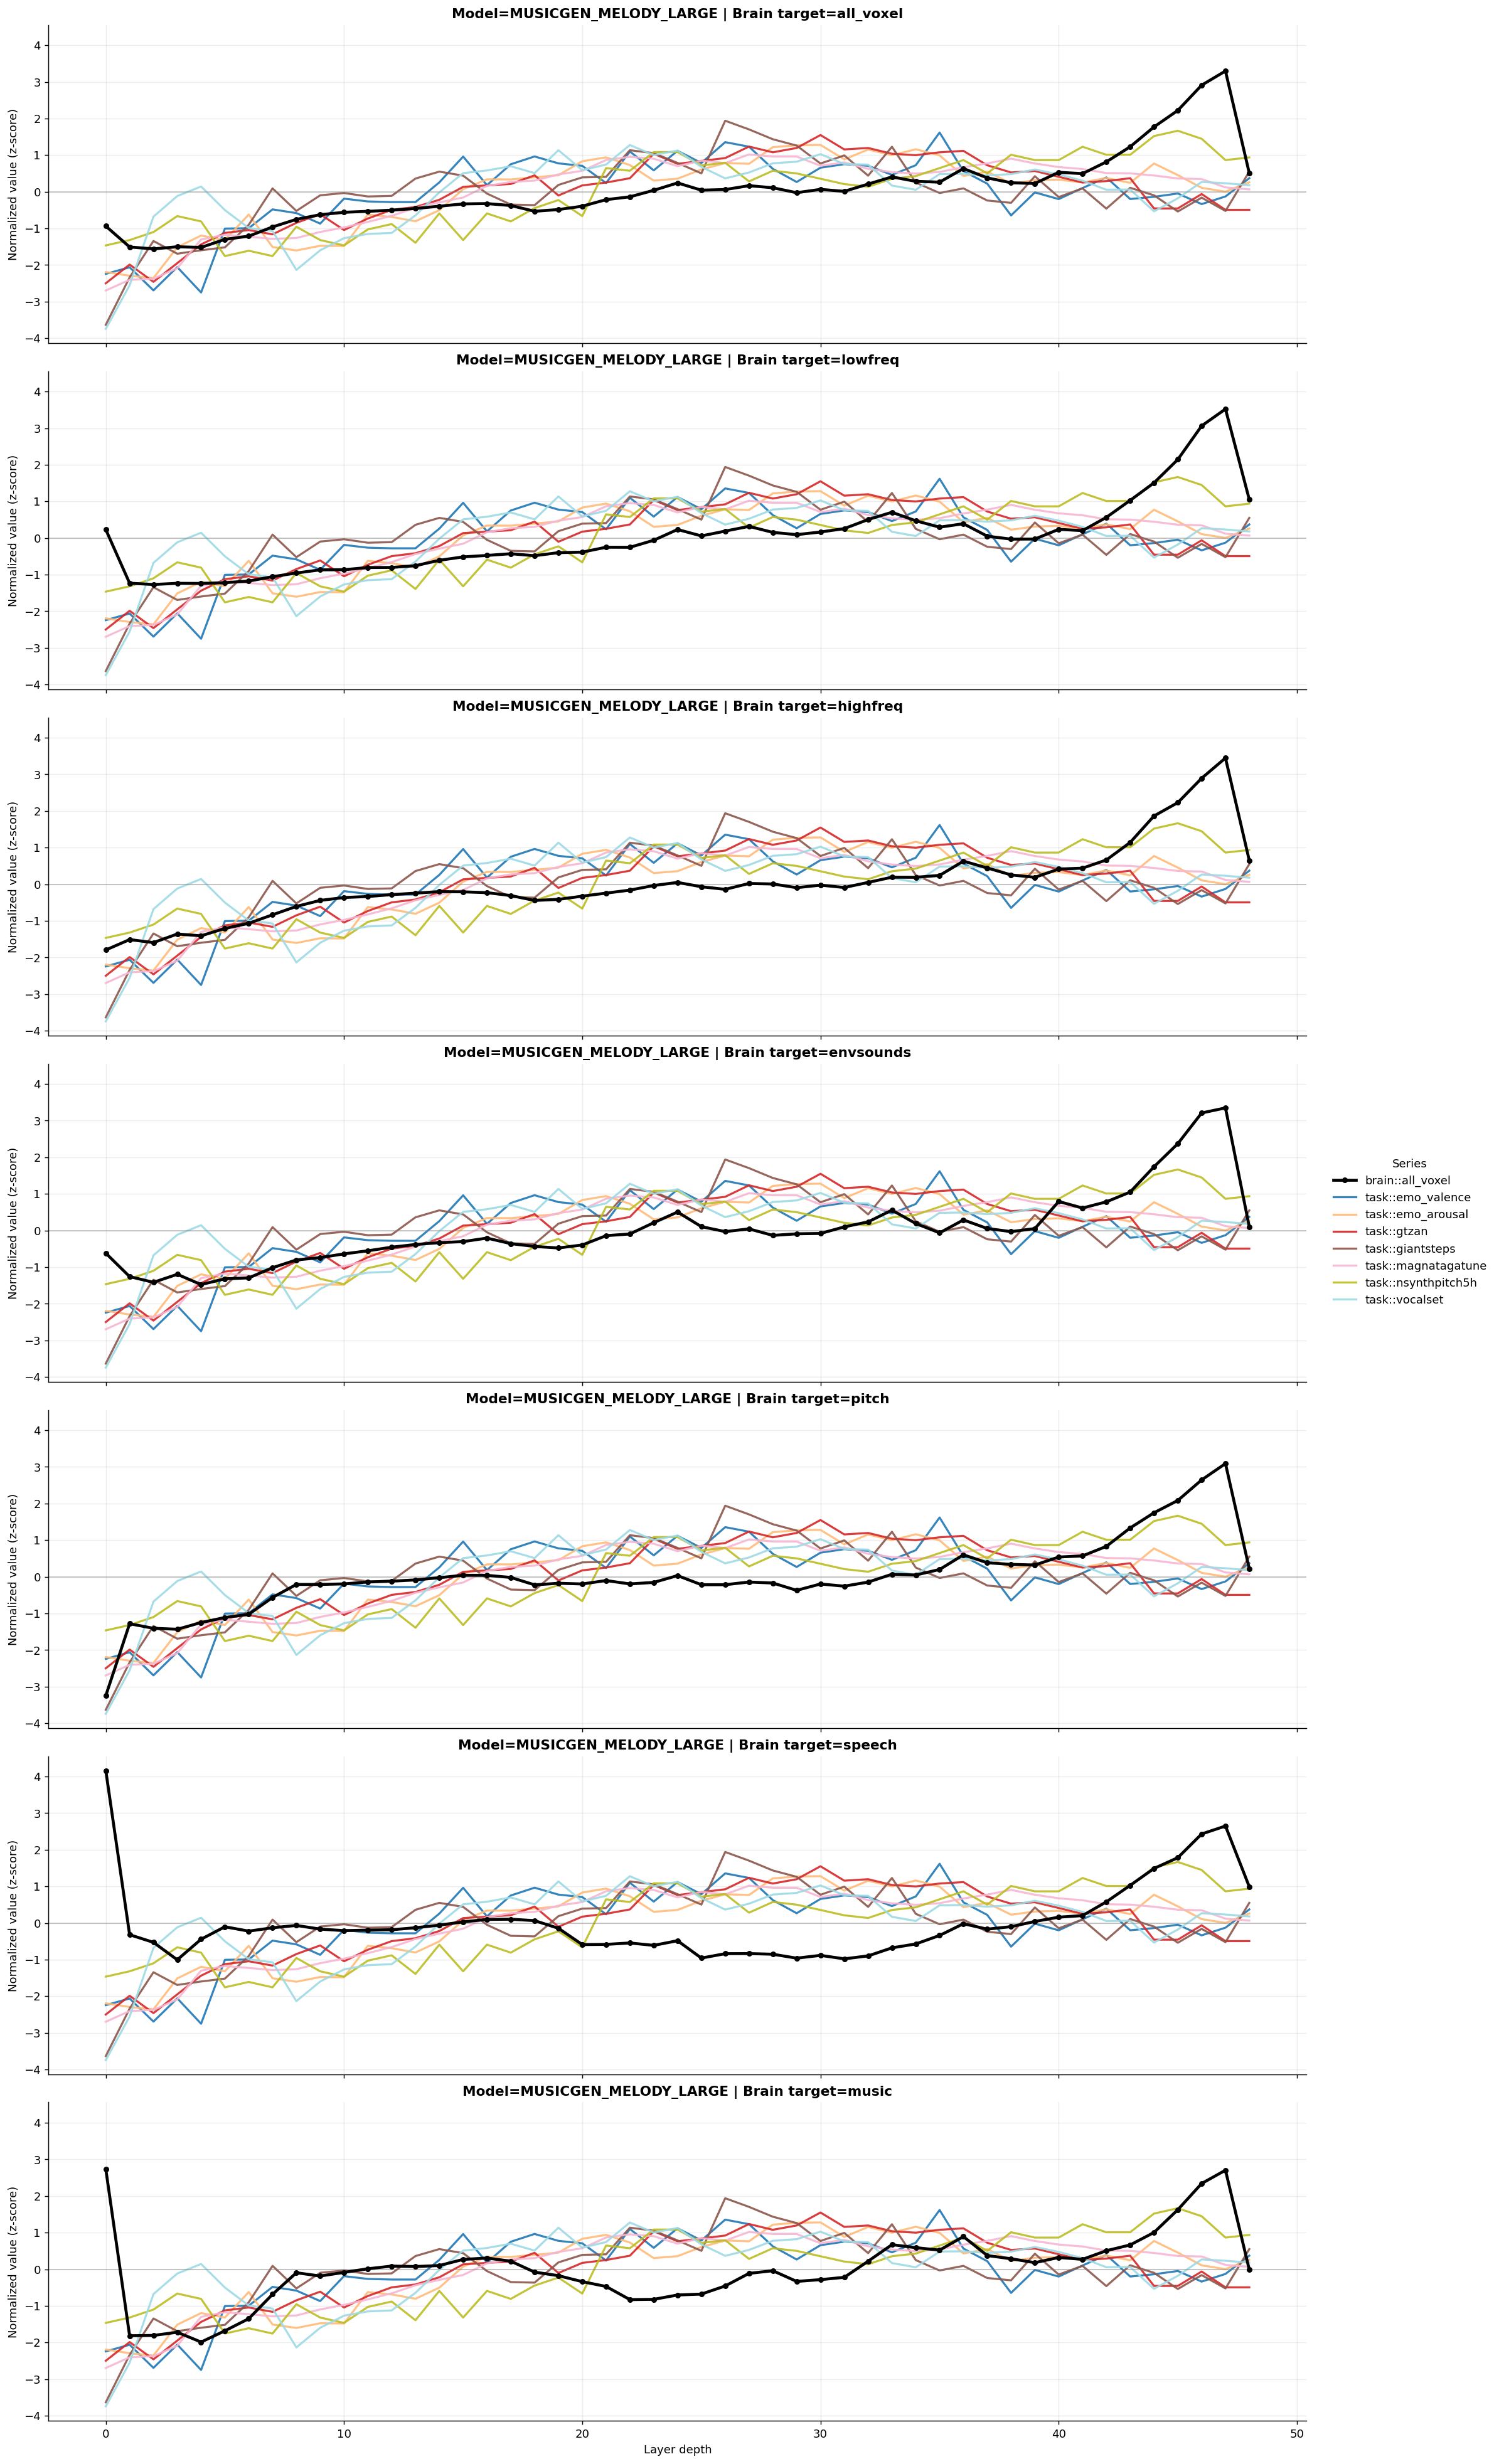

In [25]:
# 6. Selected model: layer-wise curves for chosen brain targets vs downstream tasks
selected_model_name = 'MUSICGEN_MELODY_LARGE'  # set model to inspect (CLAP, CLAP_MUSIC, CLAP_MUSIC_SPEECH, MULAN, MERT, MERT95, WAV2VEC2, MUSICGEN_SMALL, MUSICGEN_MEDIUM, MUSICGEN_LARGE, MUSICGEN_MELODY_LARGE)
selected_brain_targets = ['all_voxel', 'lowfreq', 'highfreq', 'envsounds', 'pitch', 'speech', 'music']

# Optional controls
task_labels_to_plot = [task_label for task_label, _, _, _ in task_specs]
use_relative_layer_position = False
normalize_each_curve = True  # recommended: compare layer-wise shape across heterogeneous metrics

selected_model_key = str(selected_model_name).strip().upper()
valid_models = {str(model).strip().upper() for model in MODEL_ORDER}
if selected_model_key not in valid_models:
    raise ValueError(f'Unsupported model_name: {selected_model_name}')

valid_brain_targets = {row_label for row_label, _ in brain_rows}
invalid_targets = [target for target in selected_brain_targets if target not in valid_brain_targets]
if invalid_targets:
    raise ValueError(f'Unsupported brain target(s): {invalid_targets}. Valid: {sorted(valid_brain_targets)}')

probe_layerwise_single = probe_layerwise.loc[probe_layerwise['model_key'] == selected_model_key].copy()
component_layerwise_single = component_layerwise.loc[component_layerwise['model_key'] == selected_model_key].copy()

if probe_layerwise_single.empty:
    raise RuntimeError(f'No probe rows found for model {selected_model_key}')
if component_layerwise_single.empty:
    raise RuntimeError(f'No component rows found for model {selected_model_key}')

brain_series_map_single = build_brain_series_map(probe_layerwise_single, component_layerwise_single)
task_series_map_single = build_task_series_map(probe_layerwise_single)

available_task_labels = [label for label in task_labels_to_plot if label in task_series_map_single]
if not available_task_labels:
    raise RuntimeError('No valid downstream task labels to plot.')

task_palette = plt.get_cmap('tab20')
task_colors = {
    task_label: task_palette(i / max(1, len(available_task_labels) - 1))
    for i, task_label in enumerate(available_task_labels)
}

n_rows = len(selected_brain_targets)
fig, axes = plt.subplots(
    n_rows,
    1,
    figsize=(16, 4.3 * n_rows),
    constrained_layout=True,
    sharex=True,
    sharey=normalize_each_curve,
    squeeze=False,
)
axes = axes.ravel()

for ax, brain_target in zip(axes, selected_brain_targets):
    brain_df = brain_series_map_single[brain_target].copy().sort_values('layer_depth')
    if brain_df.empty:
        ax.set_axis_off()
        ax.set_title(f'{brain_target}: no data', fontsize=11)
        continue

    if use_relative_layer_position:
        max_depth = max(float(brain_df['layer_depth'].max()), 1.0)
        brain_df['x_layer'] = brain_df['layer_depth'] / max_depth
        x_label = 'Relative layer position'
    else:
        brain_df['x_layer'] = brain_df['layer_depth']
        x_label = 'Layer depth'

    merged_curves = []
    brain_curve = brain_df[['x_layer', 'brain_score']].rename(columns={'brain_score': 'value'}).copy()
    brain_curve['series'] = f'brain::{brain_target}'
    merged_curves.append(brain_curve)

    for task_label in available_task_labels:
        task_df = task_series_map_single[task_label].copy().sort_values('layer_depth')
        if task_df.empty:
            continue
        if use_relative_layer_position:
            max_depth_task = max(float(task_df['layer_depth'].max()), 1.0)
            task_df['x_layer'] = task_df['layer_depth'] / max_depth_task
        else:
            task_df['x_layer'] = task_df['layer_depth']
        task_curve = task_df[['x_layer', 'task_score']].rename(columns={'task_score': 'value'}).copy()
        task_curve['series'] = f'task::{task_label}'
        merged_curves.append(task_curve)

    curves_long = pd.concat(merged_curves, ignore_index=True)

    if normalize_each_curve:
        curves_long['value'] = curves_long.groupby('series')['value'].transform(
            lambda s: (s - s.mean()) / (s.std(ddof=0) if s.std(ddof=0) > 0 else 1.0)
        )

    brain_plot = curves_long.loc[curves_long['series'] == f'brain::{brain_target}'].sort_values('x_layer')
    ax.plot(
        brain_plot['x_layer'],
        brain_plot['value'],
        color='black',
        linewidth=2.6,
        marker='o',
        markersize=4,
        label=f'brain::{brain_target}',
        zorder=5,
    )

    for task_label in available_task_labels:
        task_plot = curves_long.loc[curves_long['series'] == f'task::{task_label}'].sort_values('x_layer')
        if task_plot.empty:
            continue
        ax.plot(
            task_plot['x_layer'],
            task_plot['value'],
            linewidth=1.8,
            alpha=0.9,
            color=task_colors[task_label],
            label=f'task::{task_label}',
        )

    if normalize_each_curve:
        ax.axhline(0.0, color='gray', linewidth=0.9, alpha=0.5)

    ax.set_title(f"Model={selected_model_key} | Brain target={brain_target}", fontsize=12, fontweight='bold')
    ax.grid(alpha=0.22)
    if normalize_each_curve:
        ax.set_ylabel('Normalized value (z-score)')
    else:
        ax.set_ylabel('Raw score')

axes[-1].set_xlabel(x_label)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False,
    title='Series',
)

plt.show()